In [1]:
def solution(n, edges, user):
    graph = []

    for _ in range(n + 1):
        graph.append([])

    for a, b in edges:
        graph[a].append(b)
        graph[b].append(a)

    friends = set(graph[user])

    recommend = set()

    for friend in graph[user]:
        for candidate in graph[friend]:
            if candidate != user and candidate not in friends:
                recommend.add(candidate)

    return sorted(recommend)

print(solution(6,
    [[1, 2], [1, 3], [2, 4], [3, 4], [3, 5], [5, 6]],
    1))
# 출력: [4, 5]


[4, 5]


In [2]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer

# 전처리된 문서
documents = [
    "배송 빠름 상품 만족",
    "배송 지연 상품 불만",
    "배송 지연 파손"
]

# 1. TF-IDF 변환
vectorizer = TfidfVectorizer()

tfidf_matrix = vectorizer.fit_transform(documents)

# 2. 단어 목록 확인
words = vectorizer.get_feature_names_out()

# 3. DataFrame으로 변환
tfidf_df = pd.DataFrame(
    tfidf_matrix.toarray(),
    columns=words,
    index=["문서 1", "문서 2", "문서 3"]
)

print("TF-IDF 행렬:")
print(tfidf_df.round(3))

# 4. 문서별 상위 키워드 추출
print("\n문서별 상위 키워드:")

for document_name, scores in tfidf_df.iterrows():
    top_keywords = scores.nlargest(2)

    print(
        document_name,
        top_keywords.index.tolist()
    )

TF-IDF 행렬:
         만족     배송     불만     빠름     상품     지연    파손
문서 1  0.584  0.345  0.000  0.584  0.445  0.000  0.00
문서 2  0.000  0.373  0.632  0.000  0.480  0.480  0.00
문서 3  0.000  0.425  0.000  0.000  0.000  0.548  0.72

문서별 상위 키워드:
문서 1 ['만족', '빠름']
문서 2 ['불만', '상품']
문서 3 ['파손', '지연']



문서 1 주요 키워드:
만족    0.584
빠름    0.584
상품    0.445
Name: 문서 1, dtype: float64

문서 2 주요 키워드:
불만    0.632
상품    0.480
지연    0.480
Name: 문서 2, dtype: float64

문서 3 주요 키워드:
파손    0.720
지연    0.548
배송    0.425
Name: 문서 3, dtype: float64


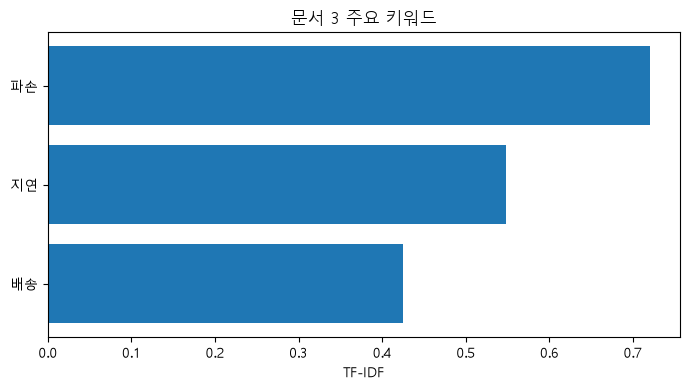

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

from sklearn.feature_extraction.text import TfidfVectorizer

# 1. 전처리된 텍스트
documents = [
    "배송 빠름 상품 만족",
    "배송 지연 상품 불만",
    "배송 지연 파손"
]

# 2. TF-IDF 행렬 생성
vectorizer = TfidfVectorizer()

tfidf_matrix = vectorizer.fit_transform(documents)

tfidf_df = pd.DataFrame(
    tfidf_matrix.toarray(),
    columns=vectorizer.get_feature_names_out(),
    index=["문서 1", "문서 2", "문서 3"]
)

# 3. 문서별 상위 키워드 확인
for document_name, scores in tfidf_df.iterrows():
    top_keywords = scores.nlargest(3)

    print(f"\n{document_name} 주요 키워드:")
    print(top_keywords.round(3))

# 4. 문서 3의 상위 키워드
top_keywords = (
    tfidf_df.loc["문서 3"]
    .nlargest(3)
    .sort_values()
)

# 5. 한글 글꼴 설정
available_fonts = {
    font.name for font in fm.fontManager.ttflist
}

for font_name in [
    "Malgun Gothic",
    "AppleGothic",
    "NanumGothic"
]:
    if font_name in available_fonts:
        plt.rcParams["font.family"] = font_name
        break

plt.rcParams["axes.unicode_minus"] = False

# 6. 막대그래프 시각화
plt.figure(figsize=(7, 4))

plt.barh(
    top_keywords.index,
    top_keywords.values
)

plt.xlabel("TF-IDF")
plt.title("문서 3 주요 키워드")

plt.tight_layout()
plt.show()

In [4]:
import pandas as pd
from kiwipiepy import Kiwi
from sklearn.feature_extraction.text import TfidfVectorizer

# 1. 원본 리뷰 5개
reviews = [
    "배송이 빨라서 만족했어요.",
    "배송이 늦어서 불만이에요.",
    "배송 중 상품이 파손되었어요.",
    "배송받은 상품의 품질에 만족해요.",
    "배송이 늦었지만 상품에는 만족해요."
]

# 2. 텍스트 정제: 앞뒤 공백 제거
cleaned_reviews = [text.strip() for text in reviews]

# 3. 기본 토큰화: 공백 기준 분리
print("기본 토큰화:")
print(cleaned_reviews[0].split())

# 4. 형태소 분석
kiwi = Kiwi()

print("\n형태소 분석:")
for token in kiwi.tokenize(cleaned_reviews[0]):
    print(token.form, token.tag)

# 5. 주요 형태소 추출
# NNG: 일반 명사, NNP: 고유 명사
# VV: 동사, VA: 형용사

def preprocess(text):
    tokens = kiwi.tokenize(text)

    words = [
        token.form
        for token in tokens
        if token.tag in ["NNG", "NNP", "VV", "VA"]
    ]

    return " ".join(words)

documents = [preprocess(text) for text in cleaned_reviews]

print("\n전처리 결과:")
for i, document in enumerate(documents, 1):
    print(f"문서 {i}: {document}")

# 6. TF-IDF 계산
vectorizer = TfidfVectorizer(
    token_pattern=r"(?u)\b\w+\b"
)

tfidf_matrix = vectorizer.fit_transform(documents)

# 7. 단어 목록 확인
words = vectorizer.get_feature_names_out()

# 8. DataFrame으로 변환
tfidf_df = pd.DataFrame(
    tfidf_matrix.toarray(),
    columns=words,
    index=[f"문서 {i}" for i in range(1, 6)]
)

print("\nTF-IDF 행렬 크기:")
print(tfidf_df.shape)

print("\nTF-IDF 행렬:")
print(tfidf_df.round(3))

# 9. 문서별 상위 키워드 2개 추출
print("\n문서별 주요 키워드:")

for document_name, scores in tfidf_df.iterrows():
    top_keywords = scores.nlargest(2)
    print(document_name, top_keywords.index.tolist())

# 10. 문서 3의 키워드별 가중치 확인
print("\n문서 3 원문:", reviews[2])

doc3_scores = tfidf_df.loc["문서 3"]
doc3_scores = doc3_scores[doc3_scores > 0]
doc3_scores = doc3_scores.sort_values(ascending=False)

print("\n문서 3 TF-IDF:")
print(doc3_scores.round(3))

기본 토큰화:
['배송이', '빨라서', '만족했어요.']

형태소 분석:
배송 NNG
이 JKS
빠르 VA
어서 EC
만족 NNG
하 XSA
었 EP
어요 EF
. SF

전처리 결과:
문서 1: 배송 빠르 만족
문서 2: 배송 늦 불만
문서 3: 배송 상품 파손
문서 4: 배송 상품 품질 만족
문서 5: 배송 늦 상품 만족

TF-IDF 행렬 크기:
(5, 8)

TF-IDF 행렬:
          늦     만족     배송    불만     빠르     상품     파손     품질
문서 1  0.000  0.517  0.368  0.00  0.773  0.000  0.000  0.000
문서 2  0.589  0.000  0.348  0.73  0.000  0.000  0.000  0.000
문서 3  0.000  0.000  0.368  0.00  0.000  0.517  0.773  0.000
문서 4  0.000  0.460  0.327  0.00  0.000  0.460  0.000  0.686
문서 5  0.606  0.503  0.358  0.00  0.000  0.503  0.000  0.000

문서별 주요 키워드:
문서 1 ['빠르', '만족']
문서 2 ['불만', '늦']
문서 3 ['파손', '상품']
문서 4 ['품질', '만족']
문서 5 ['늦', '만족']

문서 3 원문: 배송 중 상품이 파손되었어요.

문서 3 TF-IDF:
파손    0.773
상품    0.517
배송    0.368
Name: 문서 3, dtype: float64


In [5]:
import pandas as pd
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity

# 1. 검색 대상 문서
data = pd.DataFrame([
    {
        "doc_id": "Q01",
        "text": "Failure is a lesson, not the end.",
        "tags": "learning"
    },
    {
        "doc_id": "Q02",
        "text": "Every setback is a chance to try again.",
        "tags": "retry"
    },
    {
        "doc_id": "Q03",
        "text": "Small steps can create great change.",
        "tags": "progress"
    },
    {
        "doc_id": "Q04",
        "text": "Friendship is built on kindness.",
        "tags": "friendship"
    },
    {
        "doc_id": "Q05",
        "text": "Failure means you should stop trying.",
        "tags": "giving-up"
    }
])

# 2. 임베딩 모델 준비
model = SentenceTransformer(
    "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
)

# 3. 검색 대상 문서 임베딩 생성
document_vectors = model.encode(
    data["text"].tolist()
)

print("문서 임베딩 행렬 크기:")
print(document_vectors.shape)

# 4. 사용자 질문 임베딩 생성
query = "How can I keep going after repeated failures?"

query_vector = model.encode([query])

# 5. 코사인 유사도 계산
similarities = cosine_similarity(
    query_vector,
    document_vectors
)[0]

# 6. 문서별 유사도 저장
data["similarity"] = similarities

# 7. Top-3 유사 문서 검색
top_k = 3

results = (
    data.sort_values(
        "similarity",
        ascending=False
    )
    .head(top_k)
)

print("\n사용자 질문:")
print(query)

print("\nTop-3 검색 결과:")
print(
    results[
        ["doc_id", "text", "tags", "similarity"]
    ].round(3).to_string(index=False)
)

c:\TextAnalysis\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\TextAnalysis\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\mong0\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en

문서 임베딩 행렬 크기:
(5, 384)

사용자 질문:
How can I keep going after repeated failures?

Top-3 검색 결과:
doc_id                                    text      tags  similarity
   Q05   Failure means you should stop trying. giving-up       0.601
   Q02 Every setback is a chance to try again.     retry       0.496
   Q01       Failure is a lesson, not the end.  learning       0.462
